In [1]:

from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt

root = Path.cwd()
if not (root / "data").exists():
    root = root.parent

train_path = root / "data/raw/data/train/A-1.parquet"
test_path = root / "data/raw/data/test/A-1.parquet"

train = pd.read_parquet(train_path)
test = pd.read_parquet(test_path)

print("Train shape:", train.shape)
print("Test shape:", test.shape)

display(train.head())


Train shape: (2880, 26)
Test shape: (8640, 26)


,timestep,value,cmd_0,cmd_1,cmd_2,cmd_3,cmd_4,cmd_5,cmd_6,cmd_7,...,cmd_14,cmd_15,cmd_16,cmd_17,cmd_18,cmd_19,cmd_20,cmd_21,cmd_22,cmd_23
0,0,0.999,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
1,1,0.999,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
2,2,0.999,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
3,3,0.999,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
4,4,0.999,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0


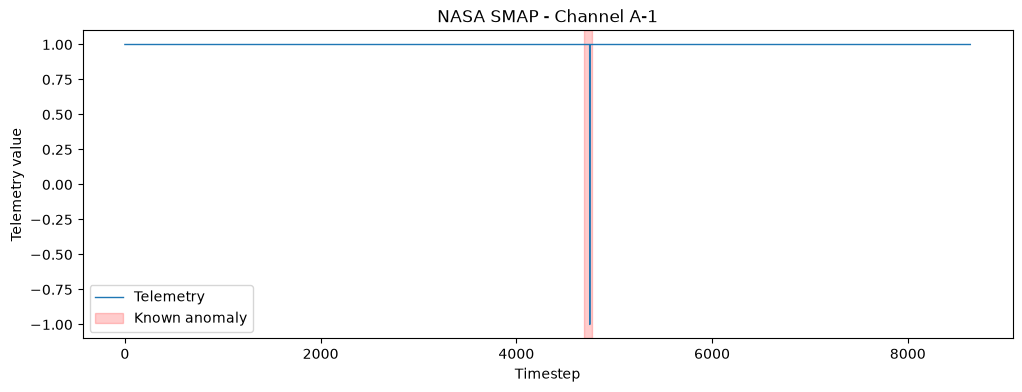

In [2]:

import ast

labels = pd.read_csv(
    root / "data/raw/labeled_anomalies.csv"
)

anomaly_text = labels.loc[
    labels["chan_id"] == "A-1",
    "anomaly_sequences"
].iloc[0]

anomaly_ranges = ast.literal_eval(anomaly_text)

fig, ax = plt.subplots(figsize=(12, 4))

ax.plot(
    test["timestep"],
    test["value"],
    label="Telemetry",
    linewidth=1
)

for start, end in anomaly_ranges:
    ax.axvspan(
        start, end,
        color="red",
        alpha=0.2,
        label="Known anomaly"
    )

ax.set_title("NASA SMAP - Channel A-1")
ax.set_xlabel("Timestep")
ax.set_ylabel("Telemetry value")
ax.legend()
plt.show()
